# Парсинг данных с сайта на premier.one

## Подключение библиотек

In [5]:
from bs4 import BeautifulSoup as bs
import requests
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import string

import re
import nltk
import pymorphy3

## Формируем ссылку на сайт

In [2]:
base_url = 'https://premier.one'
sub_url = '/collections/top-250-filmov-na-premier?page='

In [3]:
result_list = {'title': [], 'genre': [], 'year': [],
               'country': [], 'rate': [], 'description': []}

##  250 films

In [29]:
for i in range(1, 6):
    url = base_url + sub_url + str(i)
    page = requests.get(url)
    soup = bs(page.text, 'html.parser')
    links = soup.find_all('a', class_="e-poster")
    
    for link in links:
        url = base_url + link.get('href')
        page = requests.get(url)
        inner_soup = bs(page.text, 'html.parser')

        title_el = inner_soup.find('div', class_='w-show-promo-new__title-small')
        year_el = inner_soup.find('a', class_='w-show-promo-new__year-link')
        country_el = inner_soup.find('a', class_='w-show-promo-new__country-link')
        rate_el = inner_soup.find('span', class_='a-badge-rating__value')
        
        desc_v = inner_soup.find('span', class_='a-cropped-text__visible-text')
        desc_h = inner_soup.find('span', class_='a-cropped-text__hide')
        full_desc = (desc_v.text.strip() if desc_v else "") + (desc_h.text.strip() if desc_h else "")

        result_list['title'].append(title_el.text.strip() if title_el else "Без названия")
        result_list['year'].append(year_el.text.strip() if year_el else "—")
        result_list['country'].append(country_el.text.strip() if country_el else "—")
        result_list['rate'].append(rate_el.text.strip() if rate_el else "0.0")
        result_list['description'].append(full_desc if full_desc else "Нет описания")
        
        genre_els = inner_soup.find_all('a', class_='w-show-promo-new__genre-link')
        result_list['genre'].append(", ".join([i.text.strip() for i in genre_els]) if genre_els else "—")
        
        count_films += 1

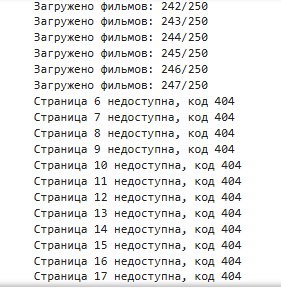

In [37]:
# Количество фильмов
count_films

494

## Сохранение в файл

In [49]:
file_name = '250films.csv'
df = pd.DataFrame(data=result_list)
df.to_csv(file_name)
df.head(10)

,title,genre,year,country,rate,description
0,1+1,"драма, комедия",2011,Франция,8.860,"Пострадав в результате несчастного случая, бог..."
1,Джентльмены,"криминал, комедия, боевик",2019,"США, Великобритания",8.674,Один ушлый американец ещё со студенческих лет ...
2,Триггер,драма,2018,Россия,8.451,Психолог Артём Стрелецкий — сторонник шоковой ...
3,Гнев человеческий,"боевик, триллер",2021,"Великобритания, США",7.714,Грузовики лос-анджелесской инкассаторской комп...
4,Брат,"драма, криминал, боевик",1997,Россия,8.371,"Демобилизовавшись, Данила Багров возвращается ..."
5,Волк с Уолл-стрит,"драма, криминал, биография, комедия",2013,США,8.100,1987 год. Джордан Белфорт становится брокером ...
6,Фишер,"детектив, драма, криминал, триллер",2023,Россия,7.853,"Интеллигентный следователь Валерий Козырев, ег..."
7,Игра престолов,"фэнтези, драма, боевик, мелодрама, приключения",2011,"США, Великобритания",9.012,"К концу подходит время благоденствия, и лето, ..."
8,Достать ножи,"детектив, комедия, драма, криминал",2019,США,8.188,На следующее утро после празднования 85-летия ...
9,Телохранители,комедия,2023,Россия,8.263,Три боксера из Челябинска перед вылетом на Чем...


In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   title        250 non-null    object 
 1   genre        250 non-null    object 
 2   year         250 non-null    int64  
 3   country      250 non-null    object 
 4   rate         250 non-null    float64
 5   description  250 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 11.8+ KB


# Работа с API

In [40]:
import requests
import pandas as pd

In [41]:
API_KEY = 'N9S9ZS6-T16MXGB-G8AAYCA-5542YYR'
BASE_URL = 'https://api.poiskkino.dev/v1/movie'
HEADERS = {'X-API-KEY': API_KEY}

## Загрузка данных полного датасета с апи и данными из сайта премьер

In [42]:
result_list = {'title': [], 'genre': [], 'year': [],
               'country': [], 'rate': [], 'description': []
              }

response = requests.get(BASE_URL, headers=HEADERS, params={'limit': 250, 'selectFields': ['name', 'genres', 'year', 'countries', 'rating', 'description']})
data = response.json()

for movie in data.get('docs', []):
    result_list['title'].append(movie.get('name', '—'))
    result_list['year'].append(movie.get('year', '—'))
    result_list['description'].append(movie.get('description', '—'))
    result_list['genre'].append(", ".join([g.get('name') for g in movie.get('genres', [])]) or "—")
    result_list['country'].append(", ".join([c.get('name') for c in movie.get('countries', [])]) or "—")
    result_list['rate'].append(movie.get('rating', {}).get('kp', 0.0))

df1 = pd.DataFrame(result_list)

In [43]:
for key, value in result_list.items():
    print(f"{key}: {len(value)}")

title: 250
genre: 250
year: 250
country: 250
rate: 250
description: 250


In [44]:
print("Количество нулевых значений в: ")
for i in result_list:
    print( i + " - " + str(result_list[i].count(None)))

Количество нулевых значений в: 
title - 0
genre - 0
year - 0
country - 0
rate - 0
description - 0


In [45]:
df1.to_csv('250apifilms.csv', index=False)
df1.head(10)

,title,genre,year,country,rate,description
0,1+1,"драма, комедия",2011,Франция,8.860,"Пострадав в результате несчастного случая, бог..."
1,Джентльмены,"криминал, комедия, боевик",2019,"США, Великобритания",8.674,Один ушлый американец ещё со студенческих лет ...
2,Триггер,драма,2018,Россия,8.451,Психолог Артём Стрелецкий — сторонник шоковой ...
3,Гнев человеческий,"боевик, триллер",2021,"Великобритания, США",7.714,Грузовики лос-анджелесской инкассаторской комп...
4,Брат,"драма, криминал, боевик",1997,Россия,8.371,"Демобилизовавшись, Данила Багров возвращается ..."
5,Волк с Уолл-стрит,"драма, криминал, биография, комедия",2013,США,8.100,1987 год. Джордан Белфорт становится брокером ...
6,Фишер,"детектив, драма, криминал, триллер",2023,Россия,7.853,"Интеллигентный следователь Валерий Козырев, ег..."
7,Игра престолов,"фэнтези, драма, боевик, мелодрама, приключения",2011,"США, Великобритания",9.012,"К концу подходит время благоденствия, и лето, ..."
8,Достать ножи,"детектив, комедия, драма, криминал",2019,США,8.188,На следующее утро после празднования 85-летия ...
9,Телохранители,комедия,2023,Россия,8.263,Три боксера из Челябинска перед вылетом на Чем...


In [46]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   title        250 non-null    object 
 1   genre        250 non-null    object 
 2   year         250 non-null    int64  
 3   country      250 non-null    object 
 4   rate         250 non-null    float64
 5   description  250 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 11.8+ KB


# Объединение файлов

In [34]:
file_html = '250films.csv'
file_api = '250apifilms.csv'

df1 = pd.read_csv(file_html)
df2 = pd.read_csv(file_api)

df_combined = pd.concat([df2, df1], ignore_index=True)

df_combined.drop(columns=['Unnamed: 0'], errors='ignore', inplace=True)

df_combined['rate'] = pd.to_numeric(df_combined['rate'], errors='coerce').fillna(0.0)
df_combined['rate'] = df_combined['rate'].round(1)


df_combined.fillna({'genre': '—', 'country': '—', 'description': 'Нет описания'}, inplace=True)

output_file = '500films.csv'
df_combined.to_csv(output_file, index=False)

print(f"Итого записей в финальном файле: {len(df_combined)}")

Итого записей в финальном файле: 497


In [54]:
df1["title"] == "1+1"

0       True
1      False
2      False
3      False
4      False
       ...  
245    False
246    False
247    False
248    False
249    False
Name: title, Length: 250, dtype: bool

In [35]:
df3 = pd.read_csv('500films.csv')
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 497 entries, 0 to 496
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   title        497 non-null    object 
 1   genre        497 non-null    object 
 2   year         497 non-null    int64  
 3   country      497 non-null    object 
 4   rate         497 non-null    float64
 5   description  497 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 23.4+ KB


In [36]:
print(df3.iloc[300])

title                                           Под Сильвер-Лэйк
genre                                Детектив, Комедия, Криминал
year                                                        2018
country                                                      США
rate                                                         6.6
description    Безработный Сэм проводит вечер с соседкой Саро...
Name: 300, dtype: object


In [37]:
df3[df3["title"] == "Вышка"]

,title,genre,year,country,rate,description
50,Вышка,триллер,2022,"Великобритания, США",6.8,После гибели Дэна в результате падения со скал...


In [38]:
df3 = pd.read_csv('500films.csv')
df3.head()

,title,genre,year,country,rate,description
0,1+1,"драма, комедия",2011,Франция,8.9,"Пострадав в результате несчастного случая, бог..."
1,Джентльмены,"криминал, комедия, боевик",2019,"США, Великобритания",8.7,Один ушлый американец ещё со студенческих лет ...
2,Триггер,драма,2018,Россия,8.5,Психолог Артём Стрелецкий — сторонник шоковой ...
3,Гнев человеческий,"боевик, триллер",2021,"Великобритания, США",7.7,Грузовики лос-анджелесской инкассаторской комп...
4,Брат,"драма, криминал, боевик",1997,Россия,8.4,"Демобилизовавшись, Данила Багров возвращается ..."


In [39]:
df3.drop_duplicates(subset=['title', 'year'], keep='first', inplace=True)
df3.dropna(subset=['title'], inplace=True)

In [40]:
df3.info

<bound method DataFrame.info of                  title                                      genre  year  \
0                  1+1                             драма, комедия  2011   
1          Джентльмены                  криминал, комедия, боевик  2019   
2              Триггер                                      драма  2018   
3    Гнев человеческий                            боевик, триллер  2021   
4                 Брат                    драма, криминал, боевик  1997   
..                 ...                                        ...   ...   
492            Офицеры                  Драма, Мелодрама, Военный  1971   
493          Итальянец                                      Драма  2005   
494   Маленькие победы                                    Комедия  2023   
495              11:14  Триллер, Драма, Детектив, Ужасы, Криминал  2003   
496             Тренер                               Драма, Спорт  2018   

                 country  rate  \
0                Франция   8.9   